Missing ini parameter: metallicity


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


Missing ini parameter: metallicity


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


Missing ini parameter: metallicity


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


Missing ini parameter: metallicity


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


Missing ini parameter: metallicity


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


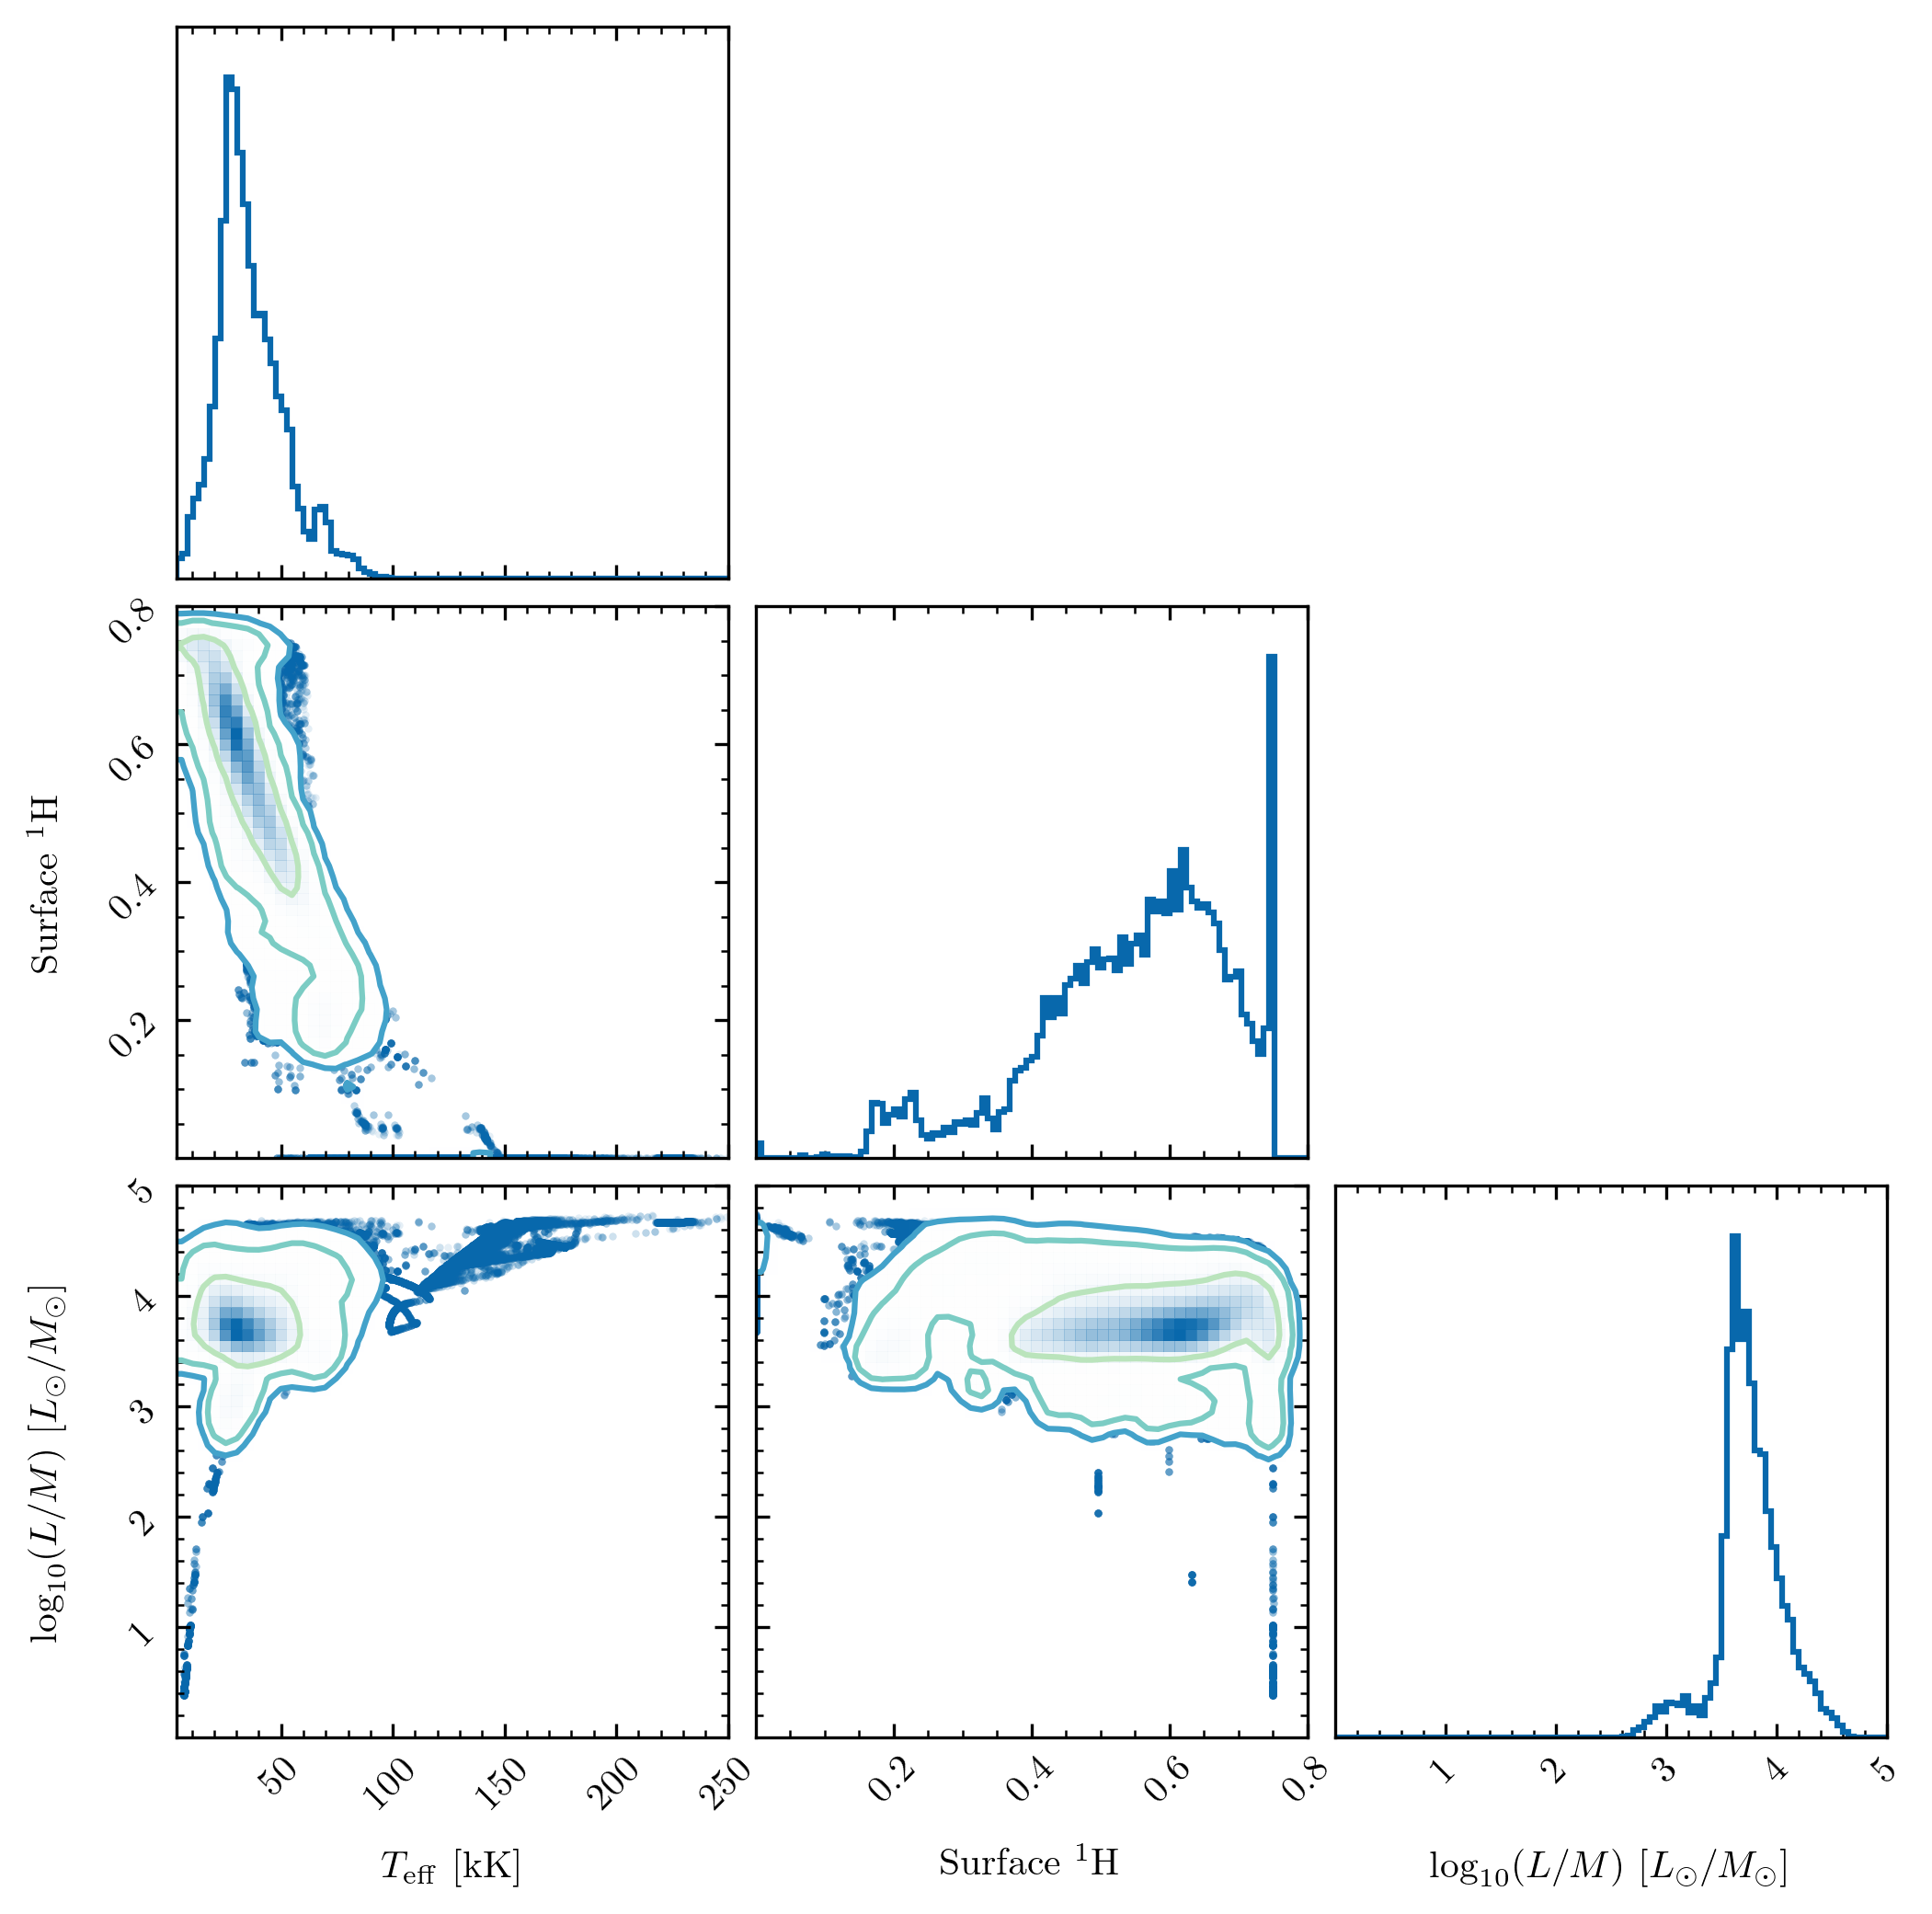

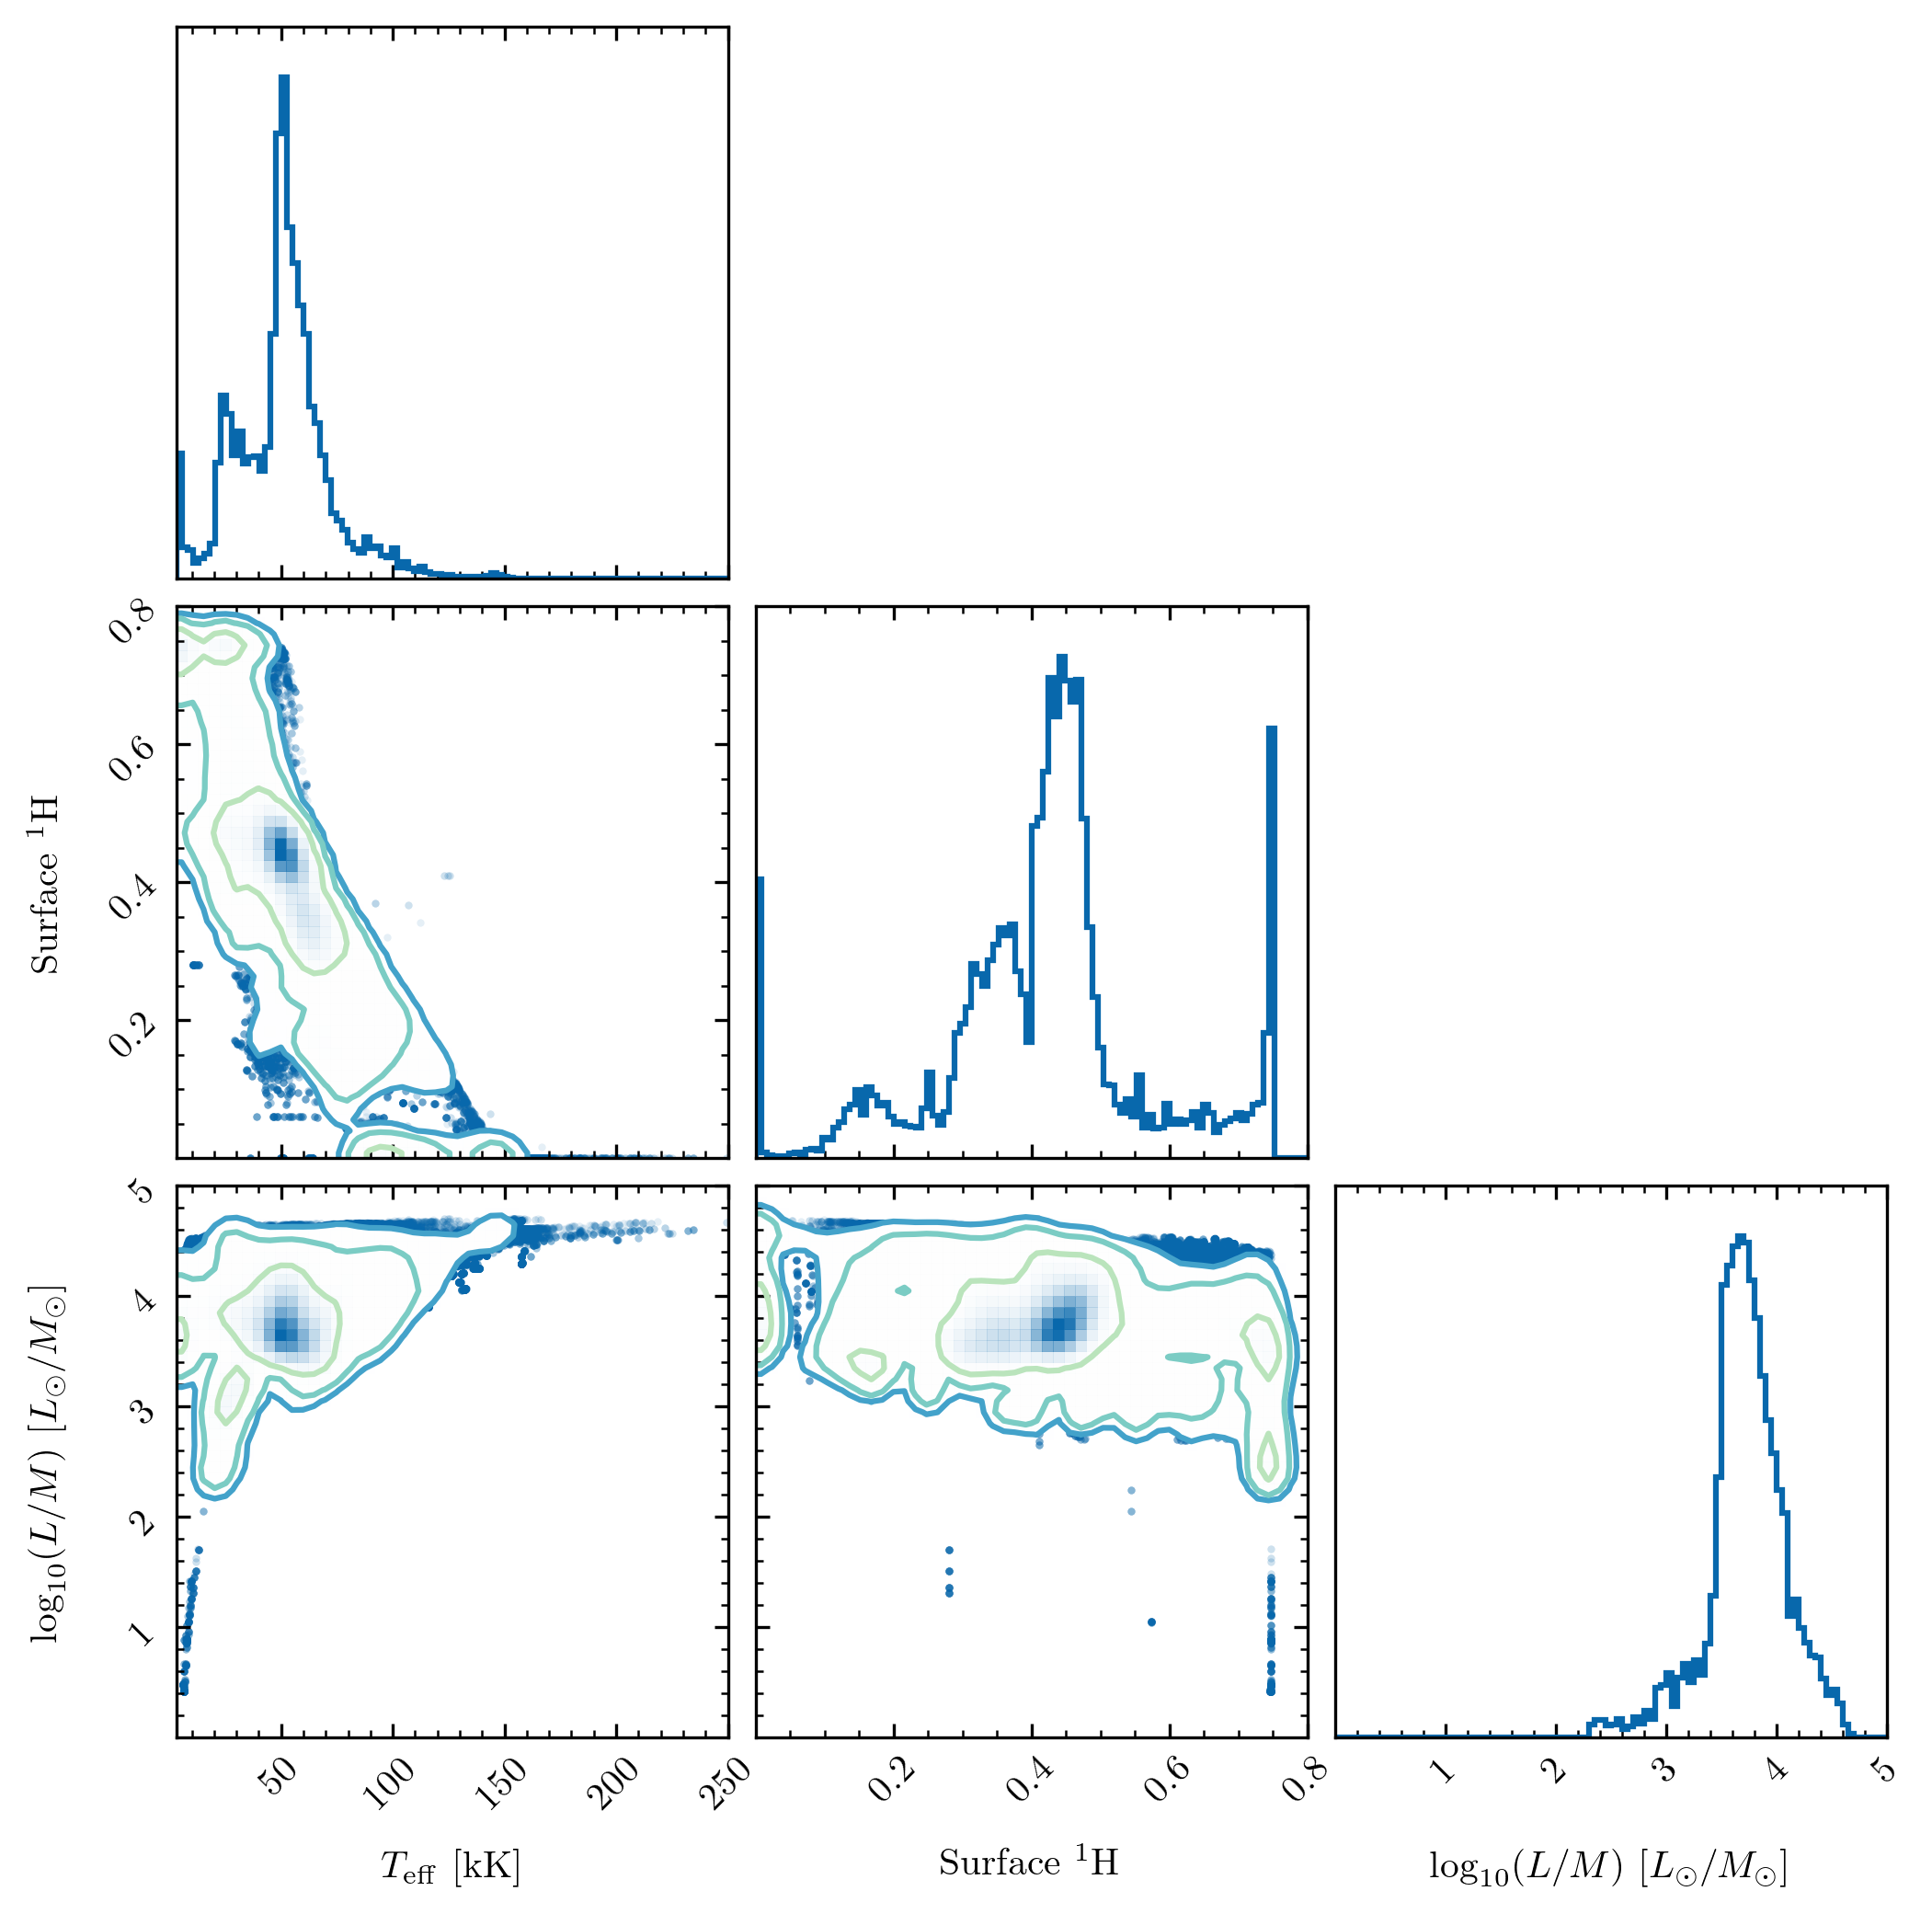

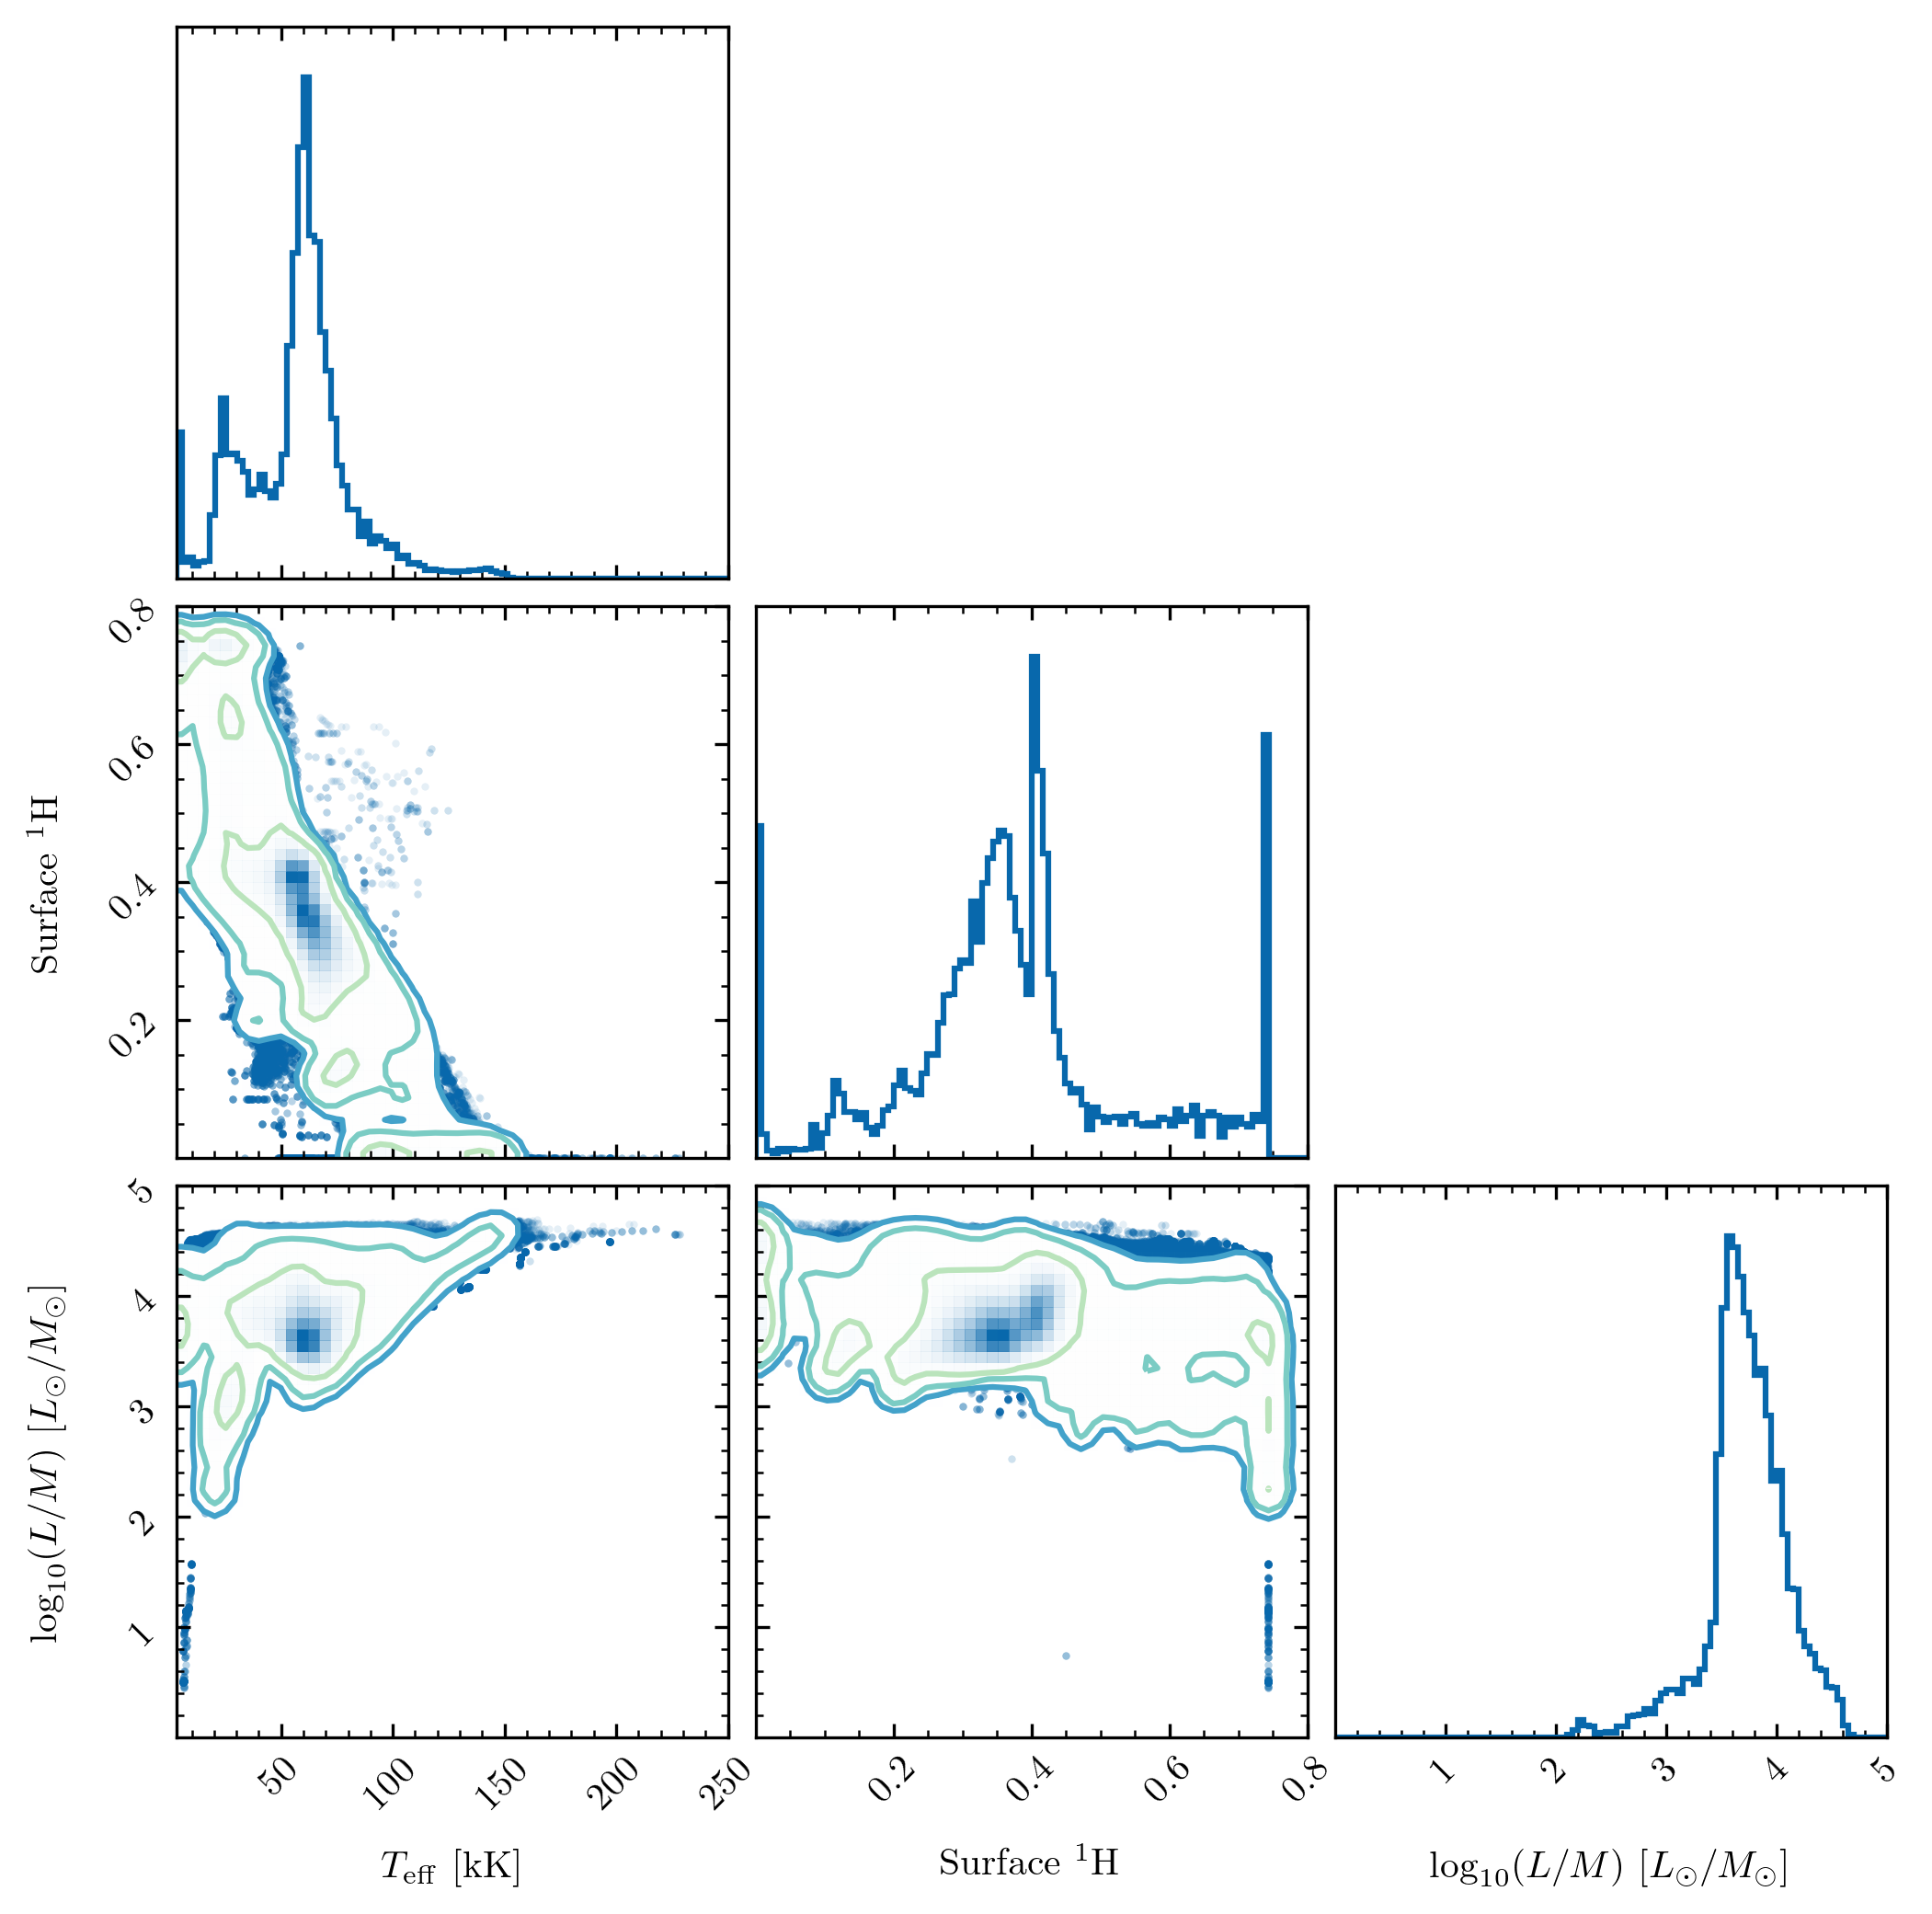

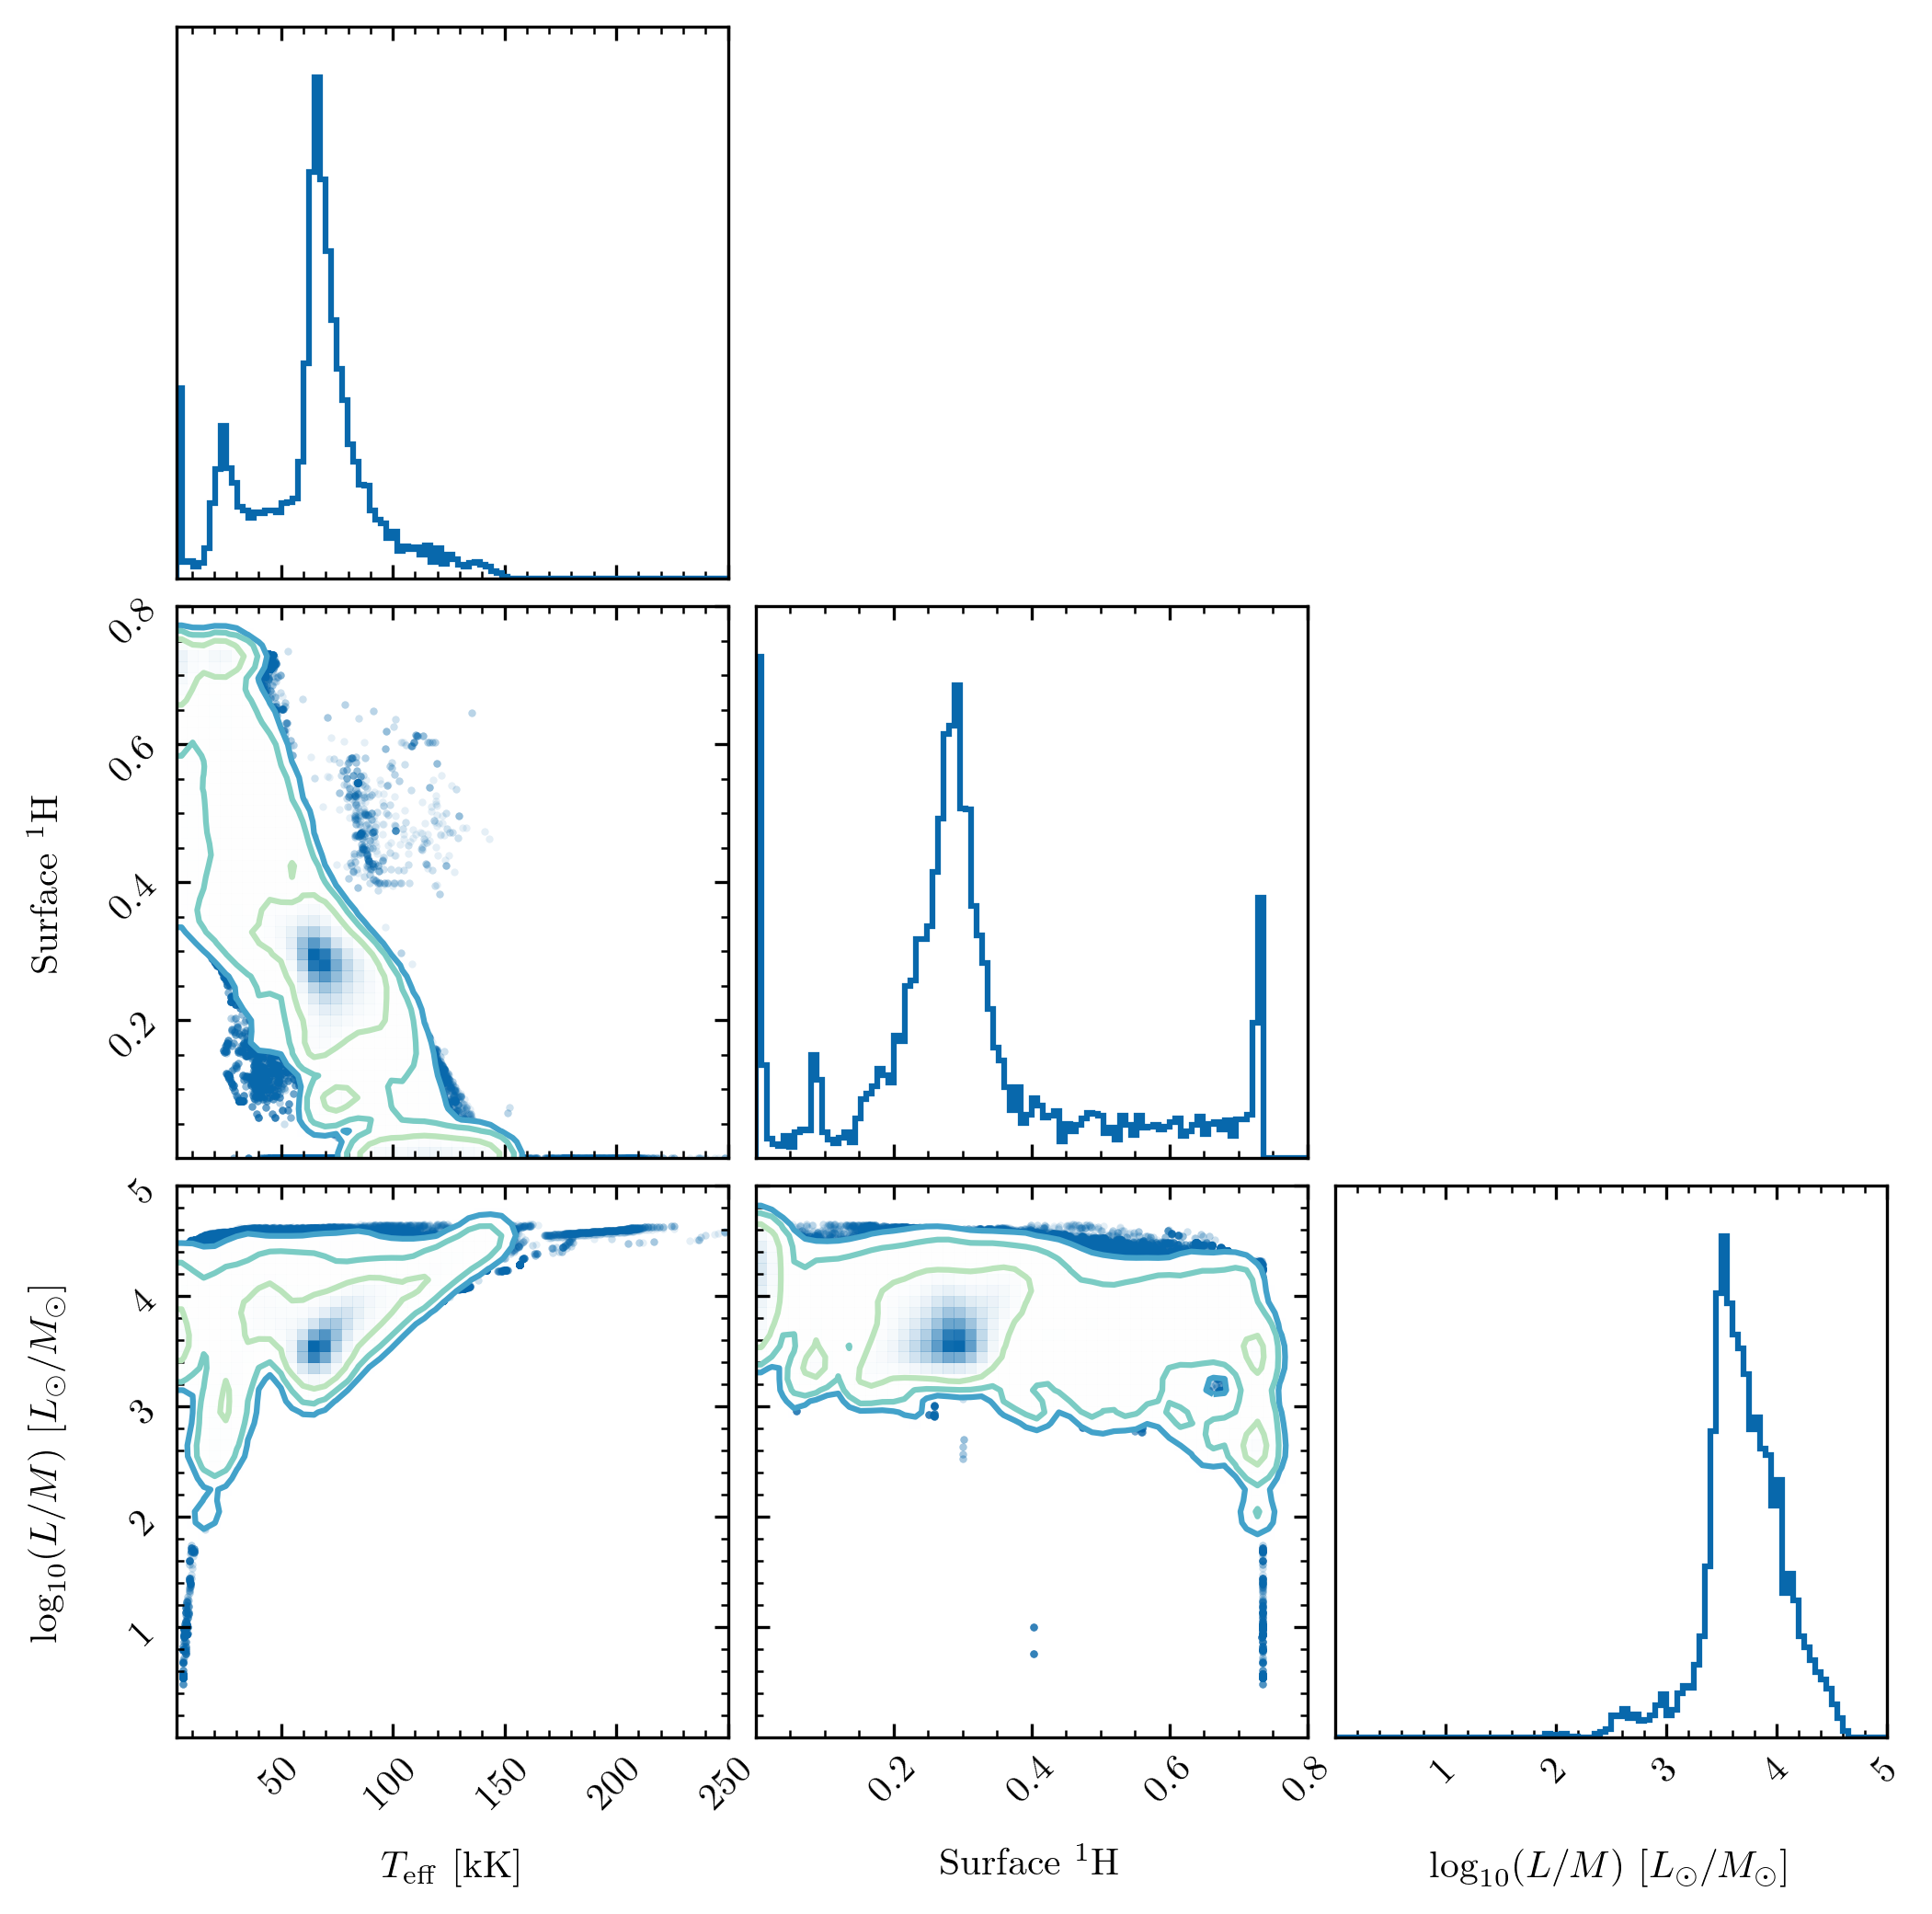

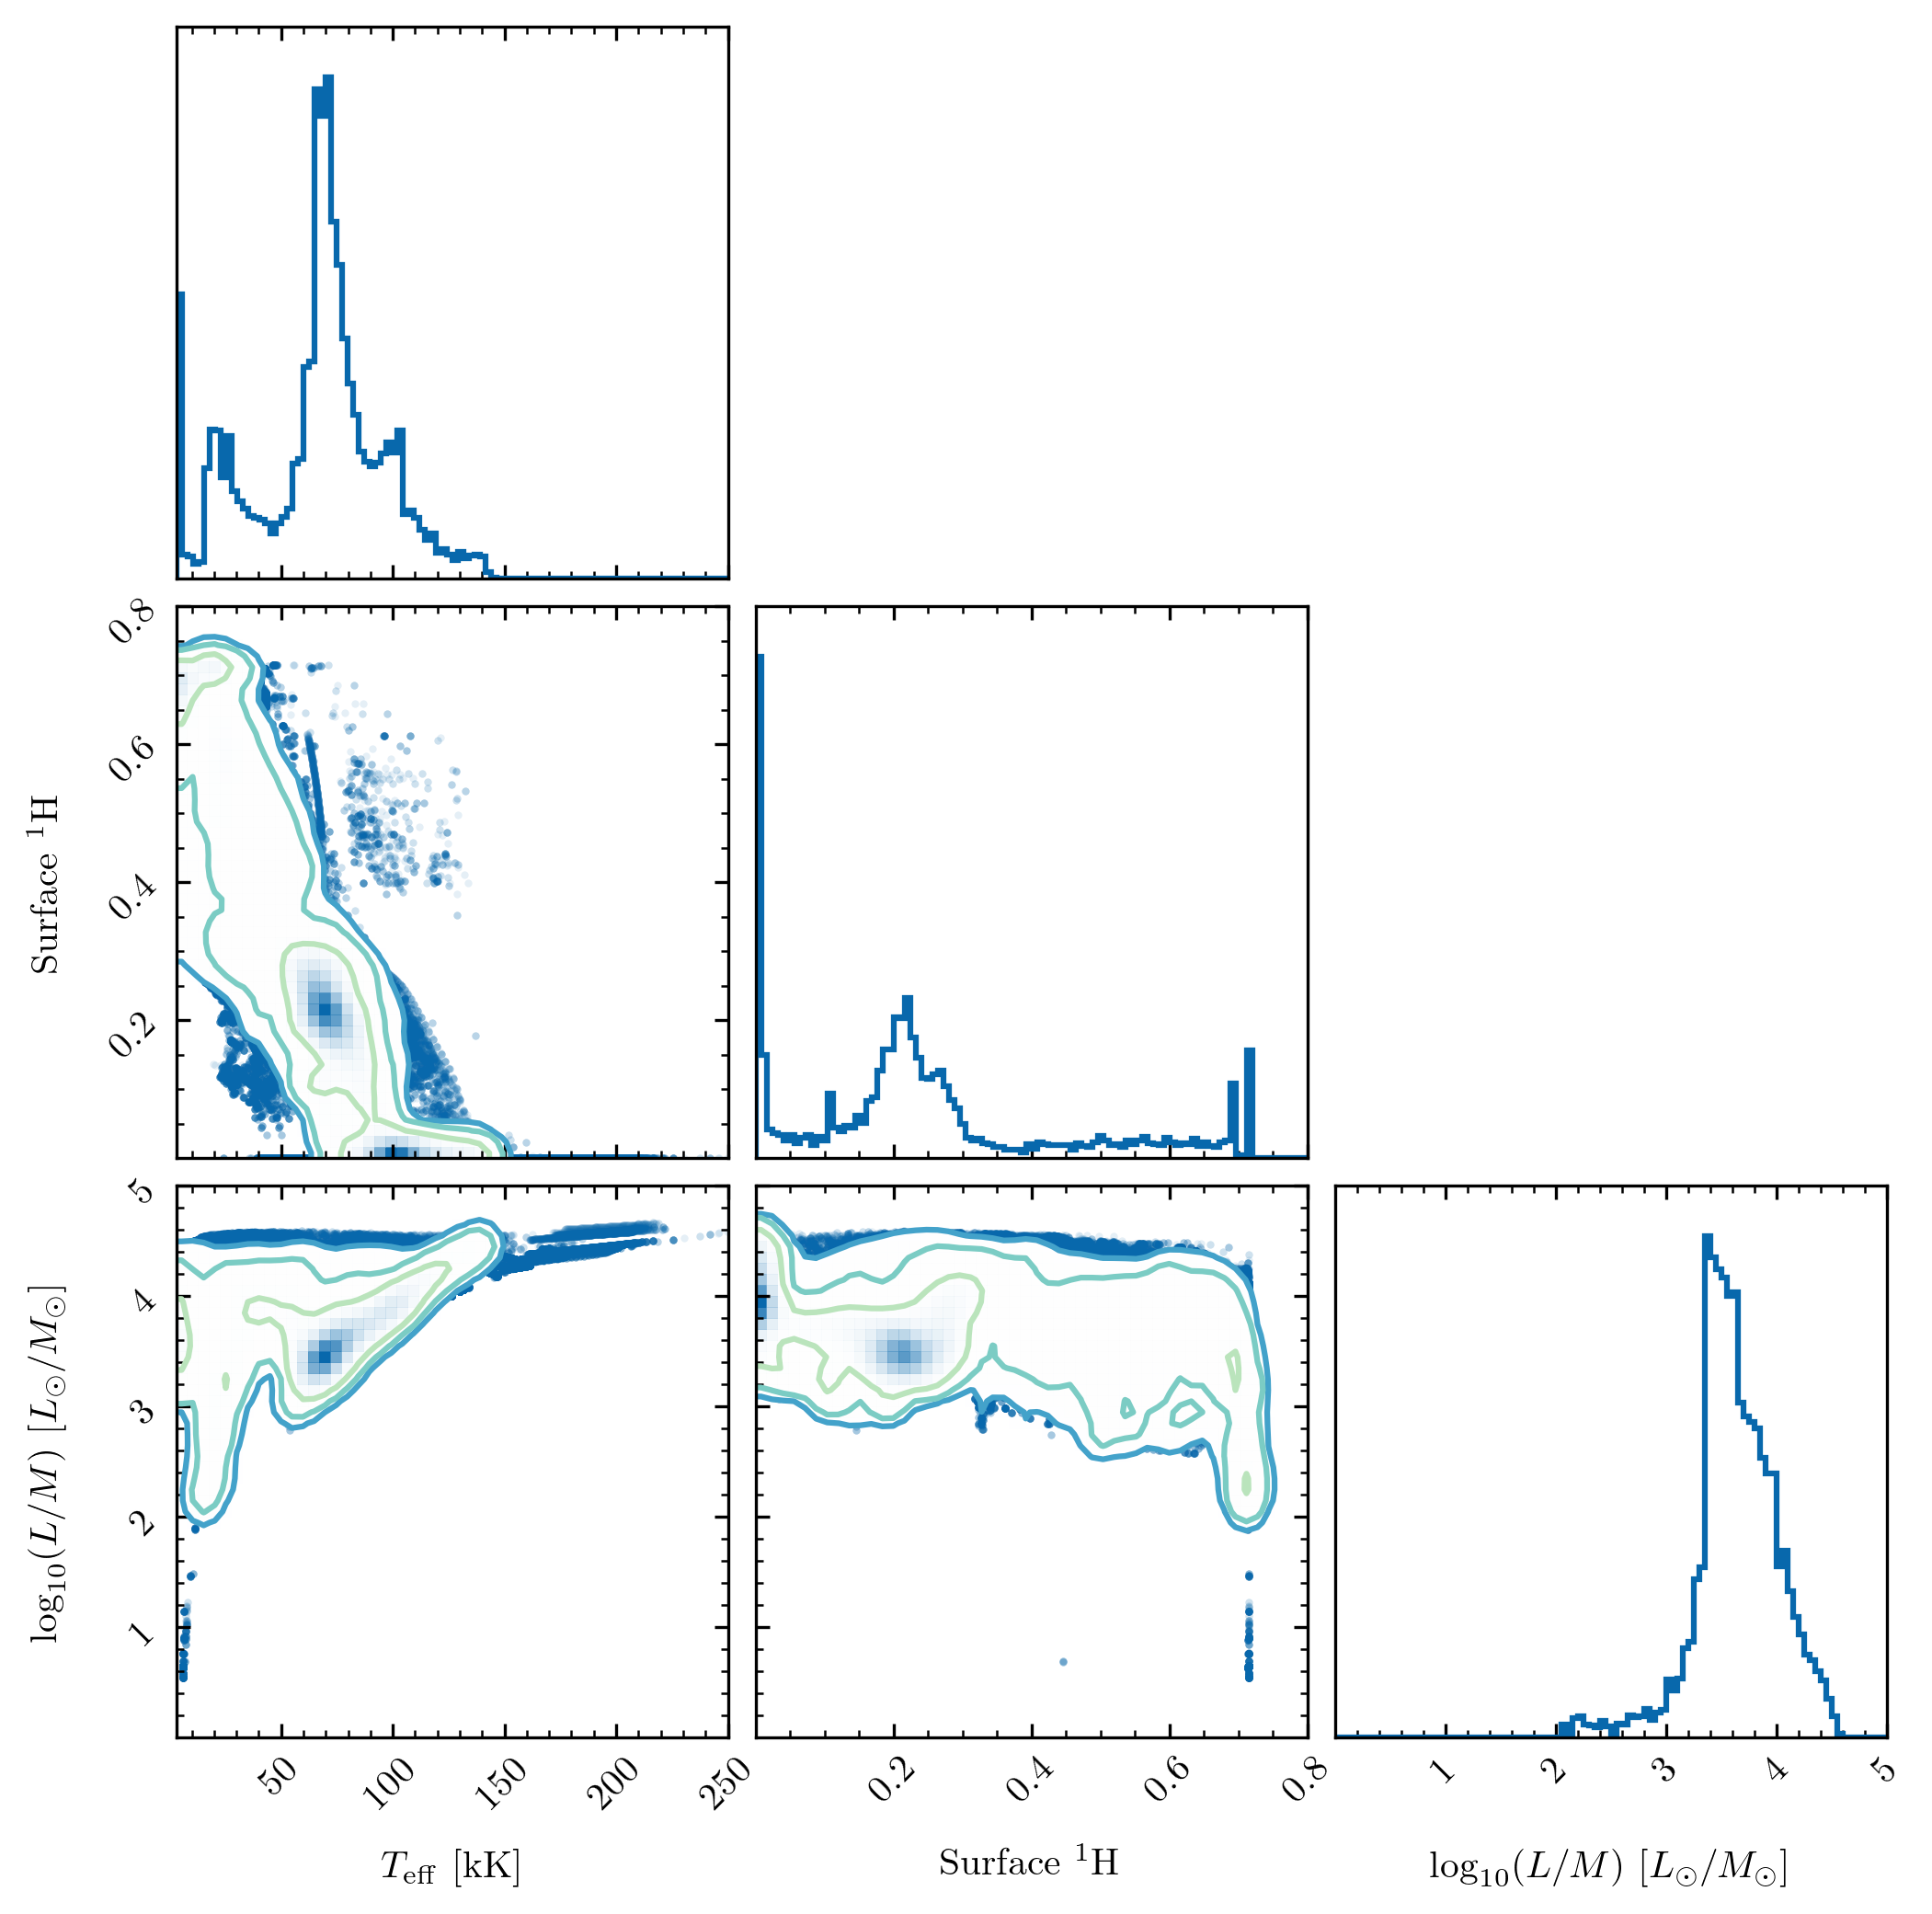

In [49]:
from posydon.utils.common_functions import convert_metallicity_to_string
import numpy as np
from posydon.popsyn.synthetic_population import Population
import matplotlib.pyplot as plt
from pathlib import Path
import corner
from posydon.config import PATH_TO_POSYDON

plt.style.use(str(Path(PATH_TO_POSYDON) / 'posydon' / 'visualization' / 'posydon.mplstyle'))

data_folder = '/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/'

for metallicity in [0.01, 0.1, 0.2, 0.45, 1]:

    met_str = convert_metallicity_to_string(metallicity)
    metallicity_file = data_folder + f"{met_str}_Zsun_population.h5"
    pop = Population(metallicity_file)
    # S1 only
    tmp_hist = pop.history[['S1_surface_h1', 'time', 'state', 'event', 'step_names', 'S1_log_L', 'S1_mass', 'S2_mass', 'orbital_period', 'S1_state', 'S2_state', 'S2_log_L', 'S1_log_R', 'S2_log_R', 'S1_surface_he4']]
    
    data_out = {}
    for i in range(pop.number_of_systems-1):
        # find RLO phase
        example = tmp_hist.loc[i]
        #example = example.reset_index()

        delta_t = example['time'].diff().fillna(0)

        mask_RLO = example['state'] == "RLO1"
        mask_CC1 = example['event'] == "CC1"

        if np.sum(mask_RLO) == 0 or np.sum(mask_CC1) == 0:
            continue
        else:
            first_index = np.where(mask_RLO.values)[0][0]
            last_index = np.where(mask_CC1.values)[0][0]
            
            # find first consecutive entries in mask that are True
            example_rlo1 = example.iloc[first_index:last_index]
            
            # S1 detached "after" mass transfer 
            mask_detached = example_rlo1['state'] == 'detached'
            example_post_rlo1 = example_rlo1[mask_detached]
            weights = delta_t.iloc[first_index:last_index][mask_detached]
            
        data_out[i] = {
            'data': example_post_rlo1,
            'weights': weights,
        }
        
    L_array = []
    M_array = []
    surface_h1_array = []
    Teff_array = []
    weights_array = []

    for key in data_out.keys():
        example_data = data_out[key]['data']
        example_weights = data_out[key]['weights']
        
        L_vals = 10**example_data['S1_log_L'].values * 3.828e26
        R_vals = 10**example_data['S1_log_R'].values* 6.957e8 
        sigma = 5.67037442e-8
        Teff_vals = (L_vals / (4 * np.pi * R_vals**2 * sigma))**0.25
        Teff_array.extend(Teff_vals)

        L_array.extend(10**example_data['S1_log_L'].values)
        M_array.extend(example_data['S1_mass'].values)
        surface_h1_array.extend(example_data['S1_surface_h1'].values)
        weights_array.extend(example_weights.values)


    labels = [
        "$T_\mathrm{eff}$ [kK]",
        "Surface ${}^1\mathrm{H}$",
        "$\log_{10}(L/M)$ [$L_\odot/M_\odot$]",
    ]

    data_array = np.column_stack([
        np.array(Teff_array)/1e3,
        np.array(surface_h1_array),
        np.log10(np.array(L_array)/np.array(M_array)),

    ])

    valid_mask = np.isfinite(data_array).all(axis=1)

    data_array_clean = data_array[valid_mask]
    weights_array_clean = np.array(weights_array)[valid_mask]

    figure = corner.corner(
        data_array_clean,
        weights=weights_array_clean,
        labels=labels,
        bins=50,
        hist_bin_factor=2,
        range=[(3,250), (0,0.8), (0, 5),],
        levels=(0.68, 0.95, 0.99),
        contour_kwargs = {'colors':( "#43a2ca", "#7bccc4", "#bae4bc",),
                        'lw':2},
        smooth=1,
        plot_datapoints=True,
        fill_contours=False,
        #contour_kwargs = {'cmap':'viridis'},
        color = "#0868ac",
        hist_kwargs = {'lw':1.5, 'color':"#0868ac"},
        labelpad=-0.1,
        )


    axes = np.array(figure.axes).reshape((3, 3))

    plt.savefig(f'{met_str}Zsun_postRLO_weighted.png', dpi=300)

In [11]:
# S1 only
tmp_hist = pop.history[['S1_surface_h1', 'time', 'state', 'event', 'step_names', 'S1_log_L', 'S1_mass', 'S2_mass', 'orbital_period', 'S1_state', 'S2_state', 'S2_log_L', 'S1_log_R', 'S2_log_R', 'S1_surface_he4']]

In [12]:
data_out = {}


for i in range(pop.number_of_systems-1):
    # find RLO phase
    example = tmp_hist.loc[i]
    #example = example.reset_index()

    delta_t = example['time'].diff().fillna(0)

    mask_RLO = example['state'] == "RLO1"
    mask_CC1 = example['event'] == "CC1"

    if np.sum(mask_RLO) == 0 or np.sum(mask_CC1) == 0:
        continue
    else:
        first_index = np.where(mask_RLO.values)[0][0]
        last_index = np.where(mask_CC1.values)[0][0]
        
        # find first consecutive entries in mask that are True
        example_rlo1 = example.iloc[first_index:last_index]
        
        # S1 detached "after" mass transfer 
        mask_detached = example_rlo1['state'] == 'detached'
        example_post_rlo1 = example_rlo1[mask_detached]
        weights = delta_t.iloc[first_index:last_index][mask_detached]
        
    data_out[i] = {
        'data': example_post_rlo1,
        'weights': weights,
    }

In [13]:
L_array = []
M_array = []
surface_h1_array = []
Teff_array = []
weights_array = []

for key in data_out.keys():
    example_data = data_out[key]['data']
    example_weights = data_out[key]['weights']
    
    L_vals = 10**example_data['S1_log_L'].values * 3.828e26
    R_vals = 10**example_data['S1_log_R'].values* 6.957e8 
    sigma = 5.67037442e-8
    Teff_vals = (L_vals / (4 * np.pi * R_vals**2 * sigma))**0.25
    Teff_array.extend(Teff_vals)

    L_array.extend(10**example_data['S1_log_L'].values)
    M_array.extend(example_data['S1_mass'].values)
    surface_h1_array.extend(example_data['S1_surface_h1'].values)
    weights_array.extend(example_weights.values)


/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'
/Users/max/Documents/projects/WR_population/analysis/software/v2.2.2/lib/python3.11/site-packages/corner/core.py:800: UserWarning: The following kwargs were not used by contour: 'lw'


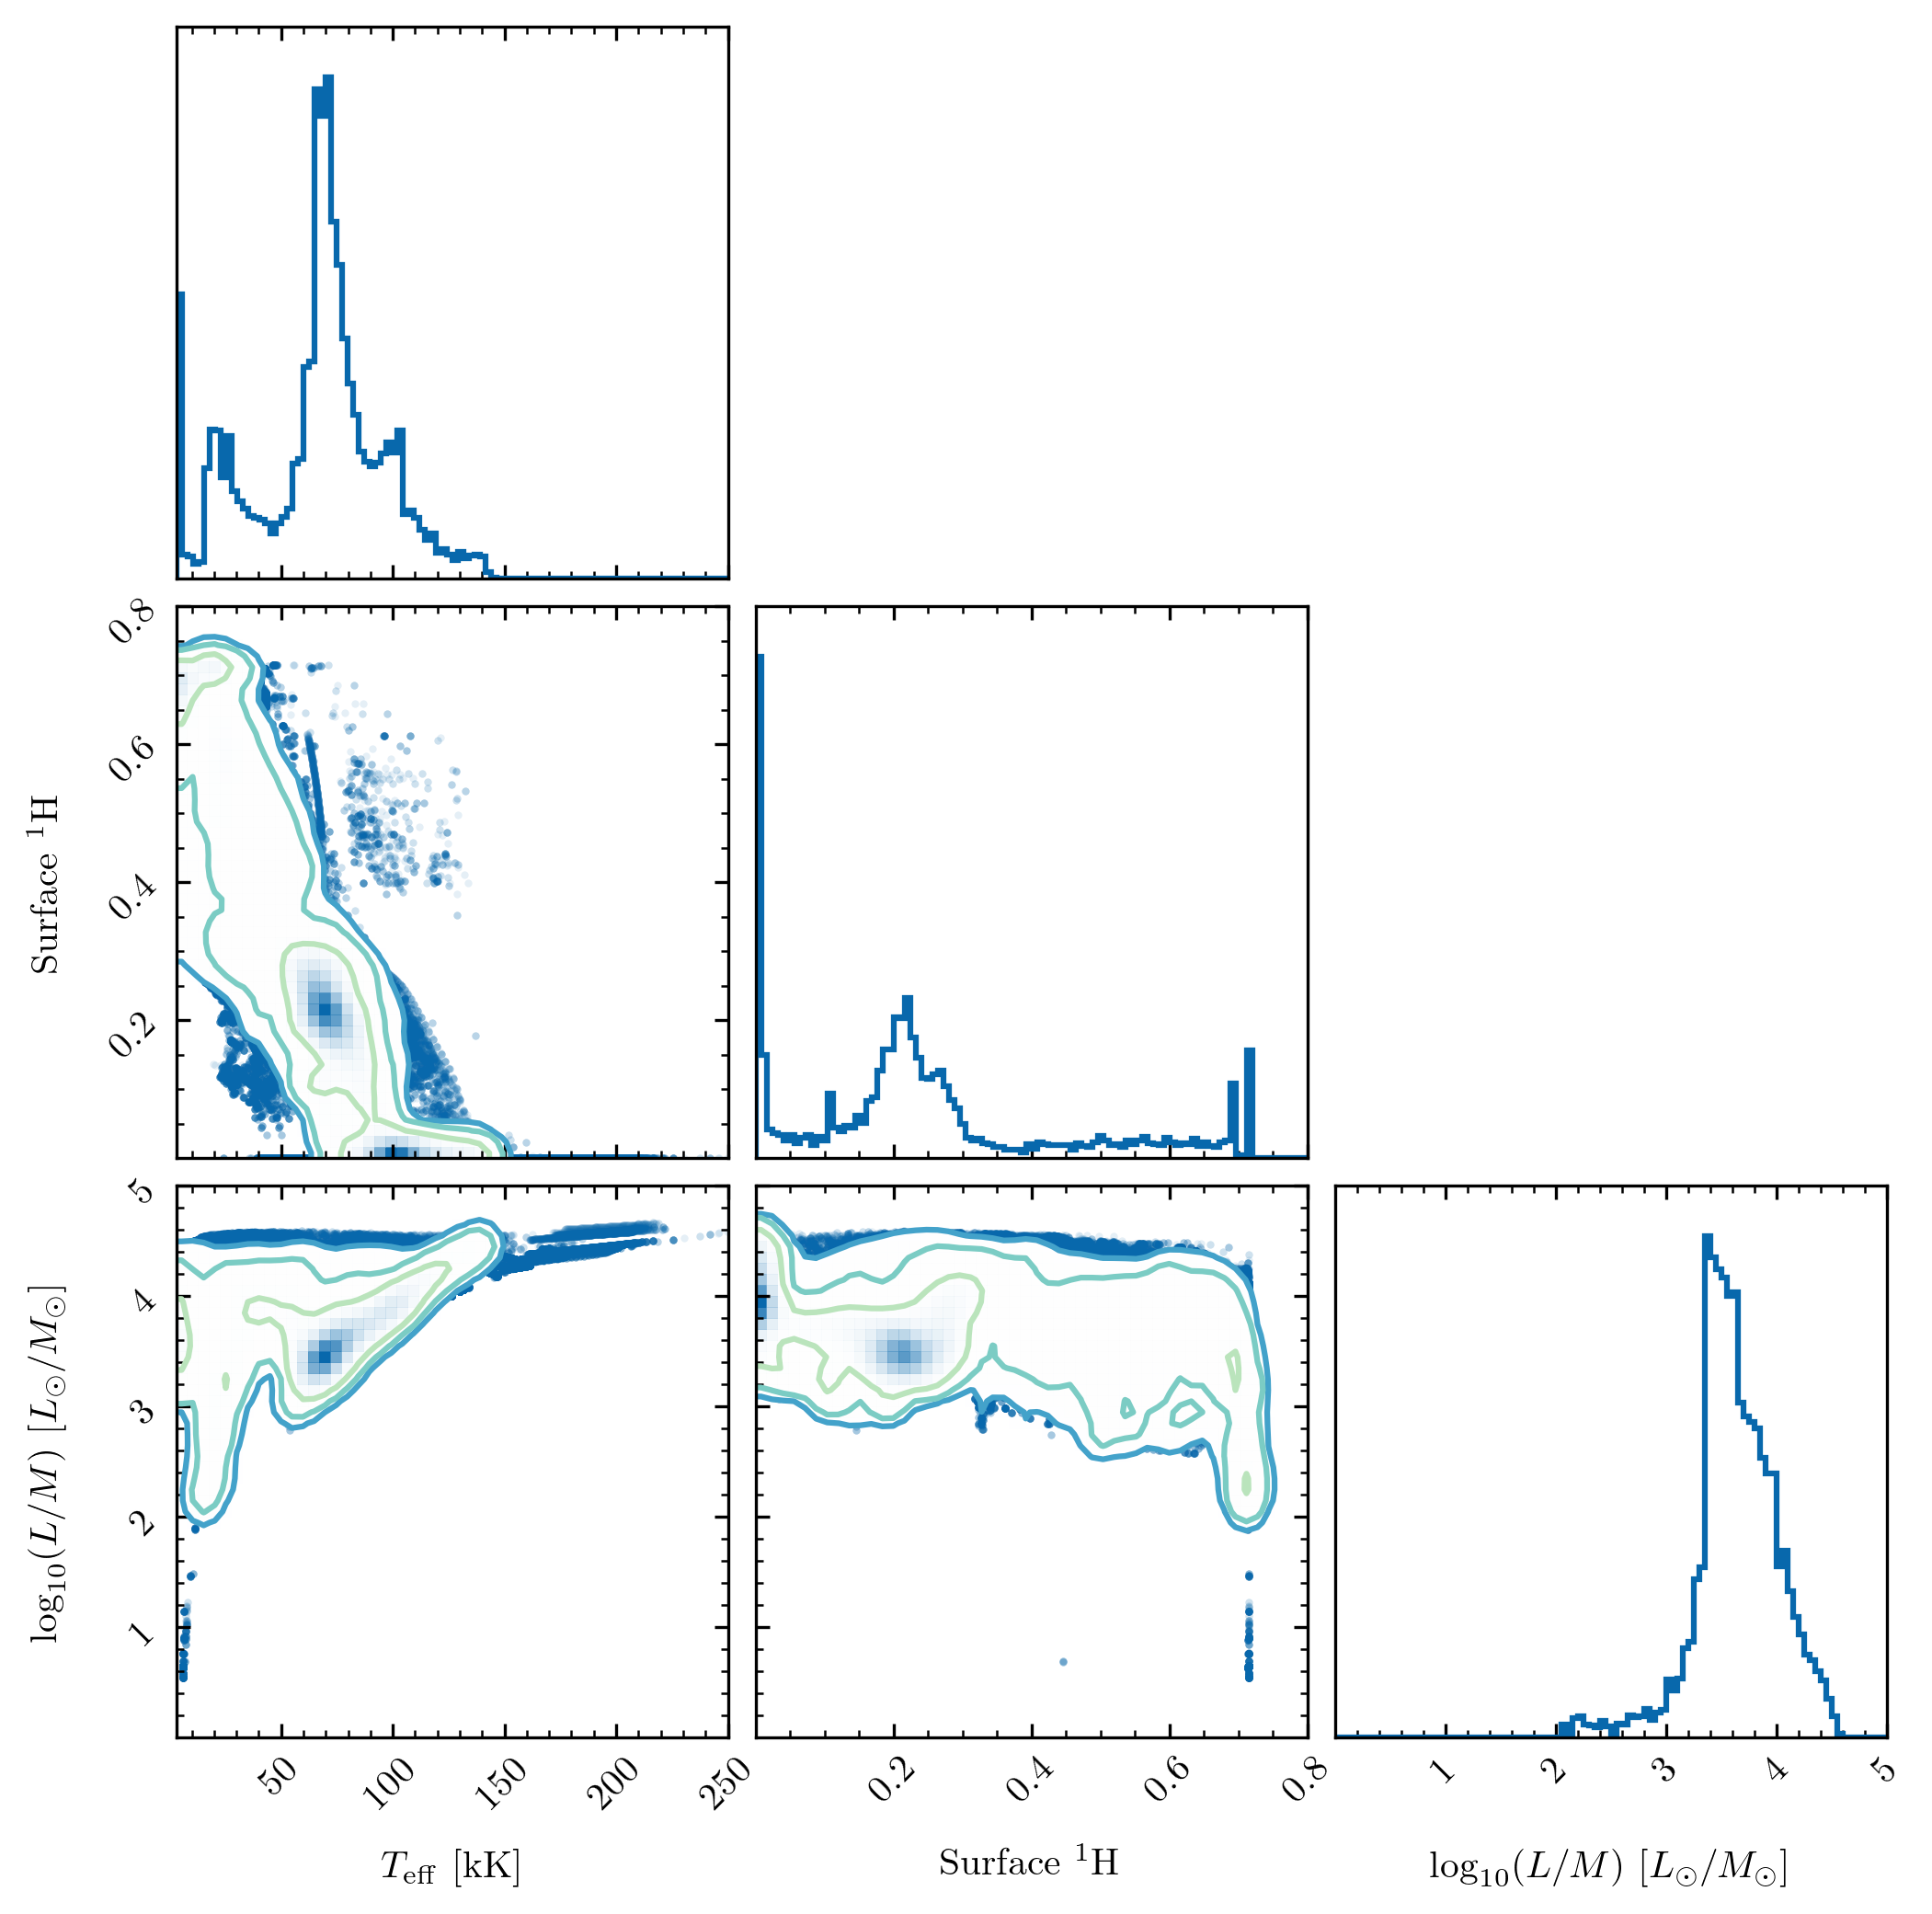

In [48]:
labels = [
    "$T_\mathrm{eff}$ [kK]",
    "Surface ${}^1\mathrm{H}$",
    "$\log_{10}(L/M)$ [$L_\odot/M_\odot$]",
]

data_array = np.column_stack([
    np.array(Teff_array)/1e3,
    np.array(surface_h1_array),
    np.log10(np.array(L_array)/np.array(M_array)),

])

valid_mask = np.isfinite(data_array).all(axis=1)

data_array_clean = data_array[valid_mask]
weights_array_clean = np.array(weights_array)[valid_mask]

figure = corner.corner(
    data_array_clean,
    weights=weights_array_clean,
    labels=labels,
    bins=50,
    hist_bin_factor=2,
    range=[(3,250), (0,0.8), (0, 5),],
    levels=(0.68, 0.95, 0.99),
    contour_kwargs = {'colors':( "#43a2ca", "#7bccc4", "#bae4bc",),
                      'lw':2},
    smooth=1,
    plot_datapoints=True,
    fill_contours=False,
    #contour_kwargs = {'cmap':'viridis'},
    color = "#0868ac",
    hist_kwargs = {'lw':1.5, 'color':"#0868ac"},
    labelpad=-0.1,
    )


axes = np.array(figure.axes).reshape((3, 3))

plt.savefig(f'{met_str}Zsun_postRLO_weighted.png', dpi=300)